# One million rows: binned P-spline learners

This study asks whether component-wise boosting can recover a known nonlinear load model when the row count makes exact spline storage the main constraint. The data are synthetic electricity-meter intervals. Synthetic data are appropriate here because the target surfaces, irrelevant covariates, and irreducible noise are known; speed and memory can therefore be evaluated without treating a fast fitted curve as evidence of statistical accuracy.

The model uses compact P-splines for temperature, time of day, and four irrelevant continuous covariates, plus compact linear learners for humidity and price. A separate test sample measures prediction. A matched exact refit on a smaller sample measures the approximation introduced by binning.

The question is when to request binned learners and how to check their
approximation. A separate test sample measures recovery, while matched smaller fits
isolate time, memory and path differences.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether component-wise boosting recovers a known load model when row count makes exact spline storage the constraint |
| **Observed response** | a simulated electricity meter reading |
| **Estimand** | the four known signal surfaces, against the irrelevant covariates |
| **Units** | simulated consumption units; time in interval index |
| **Sampling unit** | one meter-interval |
| **Dependence** | intervals from one meter are serially dependent by construction; the study's question is about storage and recovery rather than about held-out error |
| **Split / resampling unit** | the meter-interval |
| **Tuning** | fixed `mstop` |
| **Uncertainty** | recovery is checked against the known truth rather than bounded by resampling |
| **Claim type** | methodological, on synthetic data chosen so the target surfaces are known |
:::


In [1]:
import time
# Fix the random draw so the resampling result is reproducible.
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

N_TRAIN = 1_000_000
N_TEST = 100_000
BINS = 800
MSTOP = 200
NU = 0.5
NOISE_SD = 0.45

def electricity_data(n, seed):
    rng = np.random.default_rng(seed)
    data = {f"x{column}": rng.random(n) for column in range(8)}
    signal = (
        2.0
        + 3.2 * (data["x0"] - 0.5) ** 2
        + 0.8 * np.sin(2 * np.pi * data["x1"])
        + 0.8 * (data["x2"] - 0.5)
        - 0.7 * (data["x3"] - 0.5)
    )
    data["y"] = signal + rng.normal(scale=NOISE_SD, size=n)
    return data, signal

train, train_signal = electricity_data(N_TRAIN, 7)
test, test_signal = electricity_data(N_TEST, 8)
print(f"{N_TRAIN:,} training rows and {N_TEST:,} test rows")


1,000,000 training rows and 100,000 test rows


## Simulated load data

The response is measured in synthetic kilowatt-hours. `x0` represents normalized temperature and enters quadratically; `x1` represents normalized time of day and enters periodically. `x2` and `x3` are linear humidity and price effects. Covariates `x4` through `x7` are independent noise. Gaussian measurement noise has standard deviation {eval}`f"{NOISE_SD:.2f} kWh"`.

The training sample contains {eval}`f"{N_TRAIN:,}"` rows. Each exact cubic spline has roughly two dozen columns, so retaining several copies of every observation-by-basis design would dominate the model state. The compact fit requests {eval}`BINS` observation-count quantile bins per learner: each covariate is grouped into that many intervals holding equal numbers of rows, and the spline is fitted to per-bin summaries rather than to every row. The requested number of bins is written `K` below.

In [2]:
# Fit the specification stated above and retain the quantities used below.
formula = (
    "y ~ bbs(x0, center=True, df=8, boundary.knots=c(0, 1))"
    " + bbs(x1, center=True, df=8, boundary.knots=c(0, 1))"
    " + bols(x2, intercept=False)"
    " + bols(x3, intercept=False)"
    " + " + " + ".join(
        f"bbs(x{column}, center=True, df=8, boundary.knots=c(0, 1))"
        for column in range(4, 8)
    )
)
started = time.perf_counter()
path = mb.gamboost(
    formula, data=train, bins=BINS, family=mb.Gaussian(),
    control=mb.boost_control(MSTOP, NU),
)
fit_seconds = time.perf_counter() - started
report = path.execution_report()
retained_mb = report.retained_learner_bytes / 1e6
selection_counts = (
    pl.DataFrame({"learner": path.selected})
    .group_by("learner").len().rename({"len": "updates"})
    .sort("updates", descending=True)
)
selected_set = set(selection_counts["learner"])
signal_set = {"x0", "x1", "x2", "x3"}
noise_updates = int(selection_counts.filter(pl.col("learner").is_in(["x4", "x5", "x6", "x7"]))["updates"].sum())
display(selection_counts)
print(f"fit: {fit_seconds:.2f} s; retained learner data: {retained_mb:.1f} MB")


learner,updates
str,u32
"""x1""",151
"""x2""",21
"""x3""",20
"""x0""",8


fit: 2.97 s; retained learner data: 33.0 MB


## Binned fit and selected learners

The fit completes in {eval}`f"{fit_seconds:.2f} seconds"` and retains {eval}`f"{retained_mb:.1f} MB"` of learner data. All four signal learners enter, while the irrelevant learners receive {eval}`noise_updates` updates. This is a variable-selection statement under the simulated independent design; it does not imply that boosting always excludes irrelevant terms in observational data.

Time of day receives the most updates because its periodic surface has the largest residual structure after each partial update. The update count measures how the finite boosting budget is allocated, not scientific importance on a common unit scale.

mstop,test RMSE,signal RMSE
i64,f64,f64
20,0.4859,0.1842
40,0.465,0.1179
80,0.4564,0.0778
120,0.4541,0.063
160,0.4529,0.0537
200,0.4522,0.0475


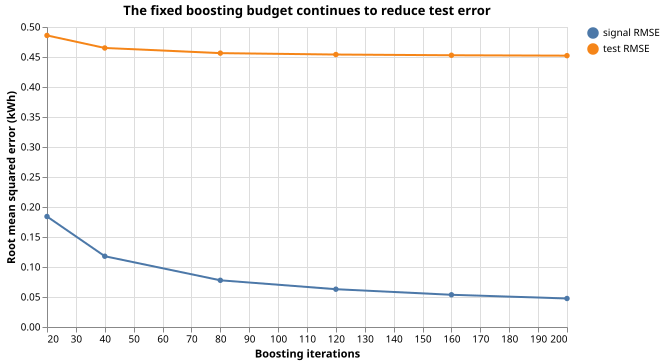

In [3]:
test_x = {name: values for name, values in test.items() if name != "y"}
risk_rows = []
for iteration in (20, 40, 80, 120, 160, 200):
    prediction = path.predict(newdata=test_x, mstop=iteration)
    risk_rows.append({
        "mstop": iteration,
        "test RMSE": float(np.sqrt(np.mean((test["y"] - prediction) ** 2))),
        "signal RMSE": float(np.sqrt(np.mean((test_signal - prediction) ** 2))),
    })
validation = pl.DataFrame(risk_rows)
budget_row = validation.filter(pl.col("mstop") == MSTOP).row(0, named=True)
test_rmse = budget_row["test RMSE"]
signal_rmse = budget_row["signal RMSE"]
display(validation.with_columns(pl.col(pl.Float64).round(4)))

alt.Chart(
    validation.unpivot(index="mstop", variable_name="quantity", value_name="RMSE"),
    title="The fixed boosting budget continues to reduce test error",
).mark_line(point=True).encode(
    x=alt.X("mstop:Q", title="Boosting iterations"),
    y=alt.Y("RMSE:Q", title="Root mean squared error (kWh)", scale=alt.Scale(zero=False)),
    color=alt.Color("quantity:N", title=None),
).properties(width=520, height=300)

The test RMSE at the fixed budget is {eval}`f"{test_rmse:.3f} kWh"`, against an irreducible noise standard deviation of {eval}`f"{NOISE_SD:.2f} kWh"`. The model's RMSE against the noise-free signal is {eval}`f"{signal_rmse:.3f} kWh"`. The validation curve is still decreasing at the budget boundary, so the fitted path is a computationally fixed comparison rather than a claim that `mstop` is optimal.

Binning and early stopping address different approximations. `K` controls the learner design; `mstop` controls how far boosting follows the selected path. A larger `K` cannot compensate for an under-extended path, and more iterations cannot recover detail removed by bins.

## Binned and exact fits on 100,000 rows

The million-row exact representation is not constructed here, because storing it would dominate memory; its estimated size is given in the selection-path section below. A matched comparison uses the first one hundred thousand training rows instead. Both fits receive the same rows, response, formula, family, step length, and stopping budget; only `bins` changes. This isolates discretization while keeping the dense exact fit practical.

In [4]:
COMPARE_N = 100_000
# Evaluate the fitted model on the study's declared rows or prediction grid.
comparison_data = {name: values[:COMPARE_N] for name, values in train.items()}

comparison_models = {}

comparison_rows = []

for representation, bins in (("exact", None), ("binned", BINS)):
    started = time.perf_counter()
    candidate = mb.gamboost(
        formula, data=comparison_data, bins=bins, family=mb.Gaussian(),
        control=mb.boost_control(MSTOP, NU),
    )
    elapsed = time.perf_counter() - started
    prediction = candidate.predict(newdata=test_x)
    comparison_models[representation] = candidate
    comparison_rows.append({
        "representation": representation,
        "engine route": candidate.execution_report().route,
        "fit seconds": elapsed,
        "retained MB": candidate.execution_report().retained_learner_bytes / 1e6,
        "test RMSE": float(np.sqrt(np.mean((test["y"] - prediction) ** 2))),
        "selected learners": ", ".join(sorted(set(candidate.selected))),
    })

comparison = pl.DataFrame(comparison_rows)

exact_comparison = comparison_models["exact"]

binned_comparison = comparison_models["binned"]


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): bbs(x1): 17.4 of 22 df after 151 selections (one step: 6.34). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


In [5]:
exact_test_prediction = exact_comparison.predict(newdata=test_x)
# Evaluate the fitted model on the study's declared rows or prediction grid.
binned_test_prediction = binned_comparison.predict(newdata=test_x)

prediction_difference = binned_test_prediction - exact_test_prediction

comparison_difference_rmse = float(np.sqrt(np.mean(prediction_difference ** 2)))

comparison_max_difference = float(np.max(np.abs(prediction_difference)))

comparison_speedup = float(comparison[0, "fit seconds"] / comparison[1, "fit seconds"])

comparison_memory_ratio = float(comparison[0, "retained MB"] / comparison[1, "retained MB"])

comparison_first_divergence = next(
    (index + 1 for index, (left, right) in enumerate(
        zip(exact_comparison.selected, binned_comparison.selected, strict=True)
    ) if left != right),
    None,
)

comparison_selected_set = set(exact_comparison.selected)

assert comparison_selected_set == set(binned_comparison.selected)

comparison_noise_names = sorted(comparison_selected_set - signal_set)

comparison_noise_updates = sum(exact_comparison.selected.count(name) for name in comparison_noise_names)

display(comparison.with_columns(pl.col(pl.Float64).round(4)))


representation,engine route,fit seconds,retained MB,test RMSE,selected learners
str,str,f64,f64,f64,str
"""exact""","""gaussian_gram""",0.1866,124.8253,0.4523,"""x0, x1, x2, x3, x5"""
"""binned""","""general""",0.3363,4.1725,0.4523,"""x0, x1, x2, x3, x5"""


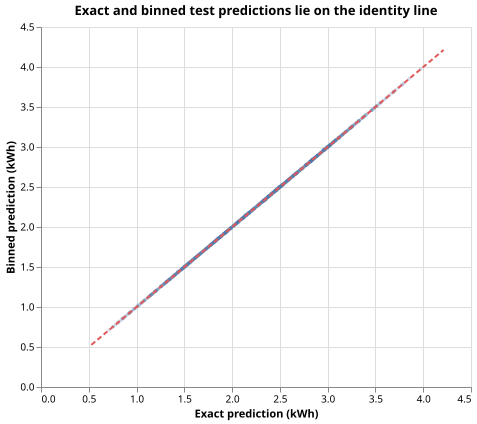

In [6]:
plot_index = np.linspace(0, N_TEST - 1, 1_000, dtype=int)
agreement = pl.DataFrame({
    "exact prediction": exact_test_prediction[plot_index],
    "binned prediction": binned_test_prediction[plot_index],
})
prediction_min = float(min(exact_test_prediction.min(), binned_test_prediction.min()))
prediction_max = float(max(exact_test_prediction.max(), binned_test_prediction.max()))
identity = pl.DataFrame({"x": [prediction_min, prediction_max], "y": [prediction_min, prediction_max]})
points = alt.Chart(agreement, title="Exact and binned test predictions lie on the identity line").mark_circle(
    size=13, opacity=0.25
).encode(
    x=alt.X("exact prediction:Q", title="Exact prediction (kWh)"),
    y=alt.Y("binned prediction:Q", title="Binned prediction (kWh)"),
)
line = alt.Chart(identity).mark_line(color="#e15759", strokeDash=[5, 3]).encode(x="x:Q", y="y:Q")
(points + line).properties(width=430, height=360)

The binned fit is {eval}`f"{comparison_speedup:.2f} times faster"` and retains {eval}`f"{comparison_memory_ratio:.0f} times less learner data"` in the matched comparison. Its predictions differ from the exact fit by {eval}`f"{comparison_difference_rmse:.4f} kWh RMSE"`, which is {eval}`f"{100 * comparison_difference_rmse / NOISE_SD:.2f}%"` of the observation-noise standard deviation. The largest pointwise difference is {eval}`f"{comparison_max_difference:.3f} kWh"`.

Both paths select the same learner set. On the smaller comparison sample, each path gives {eval}`comparison_noise_updates` late update to the same noise learner; the million-row fit gives noise learners none. Their first selection difference occurs at update {eval}`comparison_first_divergence`, near the end of the fixed budget, after which substitute updates within the same selected set produce the small prediction discrepancy shown by the identity chart. Equivalent predictive results do not require a bit-identical late path when candidate improvements have become nearly tied.

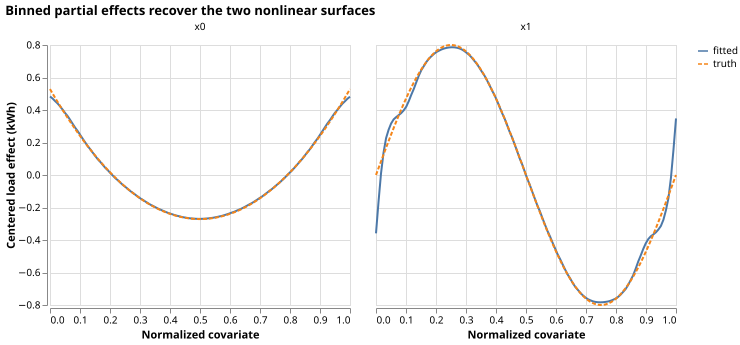

In [7]:
effect_rows = []
truth_functions = {
    "x0": lambda values: 3.2 * (values - 0.5) ** 2,
    "x1": lambda values: 0.8 * np.sin(2 * np.pi * values),
}
for learner in ("x0", "x1"):
    values, fitted_effect = path.partial_effects(which=learner, n_points=120)[learner]
    truth = truth_functions[learner](np.asarray(values))
    fitted_effect = np.asarray(fitted_effect) - np.mean(fitted_effect)
    truth = truth - np.mean(truth)
    effect_rows.extend({"learner": learner, "x": float(x), "effect": float(y), "source": "fitted"}
                       for x, y in zip(values, fitted_effect, strict=True))
    effect_rows.extend({"learner": learner, "x": float(x), "effect": float(y), "source": "truth"}
                       for x, y in zip(values, truth, strict=True))
effects = pl.DataFrame(effect_rows)
alt.Chart(effects, title="Binned partial effects recover the two nonlinear surfaces").mark_line().encode(
    x=alt.X("x:Q", title="Normalized covariate"),
    y=alt.Y("effect:Q", title="Centered load effect (kWh)"),
    color=alt.Color("source:N", title=None),
    strokeDash=alt.StrokeDash("source:N", title=None),
    column=alt.Column("learner:N", title=None),
).properties(width=300, height=260)

The temperature and time-of-day effects reproduce the simulated shapes on the observed support. Their magnitudes remain shrunken because the boosting path stops before full convergence to the unpenalised fit. The relevant evidence is agreement in shape and declining signal RMSE, not equality of unshrunk amplitudes.

In [8]:
started = time.perf_counter()
bin_check = path.check_binning(n=15_000, seed=19, mstop=80)
check_seconds = time.perf_counter() - started
estimated_exact_full_mb = (
    bin_check["exact_retained_learner_bytes"] / bin_check["n"] * N_TRAIN / 1e6
)
pl.DataFrame([{
    "subsample rows": bin_check["n"],
    "checked mstop": bin_check["mstop"],
    "selection sequence identical": bin_check["selection_sequence_identical"],
    "first divergence": bin_check["first_selection_divergence"],
    "max difference / residual SD": bin_check["relative_to_residual_sd"],
    "estimated full exact learner MB": estimated_exact_full_mb,
}]).with_columns(pl.col(pl.Float64).round(3))

subsample rows,checked mstop,selection sequence identical,first divergence,max difference / residual SD,estimated full exact learner MB
i64,i64,bool,null,f64,f64
15000,80,true,null,0.048,1249.69


## Selection-path agreement: `check_binning`

The matched check, `check_binning`, compares the binned and exact fits' selection sequences (the order in which learners are picked) and completes in {eval}`f"{check_seconds:.2f} seconds"`. Its compact and exact fits use the same {eval}`bin_check['n']` rows and retain the same selection sequence through {eval}`bin_check['mstop']` updates. The maximum fitted discrepancy is {eval}`f"{bin_check['relative_to_residual_sd']:.3f}"` residual standard deviations.

Scaling the exact subsample's retained learner bytes linearly to the full row count gives approximately {eval}`f"{estimated_exact_full_mb:.0f} MB"`, compared with the measured compact fit's {eval}`f"{retained_mb:.1f} MB"`. This scaling describes retained learner state only; input arrays, Python objects, fitted paths, and allocator overhead remain outside it.

In [9]:
sensitivity_rows = []
for bins in (50, 200, 800):
    if bins == BINS:
        candidate = path
        seconds = fit_seconds
    else:
        started = time.perf_counter()
        candidate = mb.gamboost(
            formula, data=train, bins=bins, family=mb.Gaussian(),
            control=mb.boost_control(MSTOP, NU),
        )
        seconds = time.perf_counter() - started
    prediction = candidate.predict(newdata=test_x)
    sensitivity_rows.append({
        "bins": bins,
        "fit seconds": seconds,
        "retained MB": candidate.execution_report().retained_learner_bytes / 1e6,
        "test RMSE": float(np.sqrt(np.mean((test["y"] - prediction) ** 2))),
        "noise updates": sum(name in {"x4", "x5", "x6", "x7"}
                             for name in candidate.selected),
    })
sensitivity = pl.DataFrame(sensitivity_rows)
display(sensitivity.with_columns(pl.col(pl.Float64).round(3)))

bins,fit seconds,retained MB,test RMSE,noise updates
i64,f64,f64,f64,i64
50,2.809,32.085,0.453,0
200,3.094,32.262,0.452,0
800,2.973,32.973,0.452,0


## Sensitivity to the bin count

The sensitivity table holds the data, learner menu, step length, and boosting budget fixed. It changes only the requested bin count. The comparison therefore isolates discretization rather than mixing it with a different stopping path or sample.

A useful `K` is the smallest value whose predictive error, interpreted surfaces, and selection path are stable enough for the analysis. The largest value is not automatically preferable: it increases compact basis work and memory while approaching an exact representation that may be unnecessary relative to sampling noise.

## Conclusions and limitations

The case establishes an implementation claim and a simulation claim. The implementation retains a million-row, eight-learner additive model without dense observation-by-basis designs. Under this independent synthetic design, the finite path selects only the four covariates that generated load and recovers the two nonlinear shapes.

It does not establish a universal bin count or a causal electricity-demand model. Correlated covariates can change the selection path; narrow local features need more bins; tied or discrete covariates can yield fewer occupied cells than requested; and the stopping budget remains a separate source of shrinkage. `check_binning()` should be run again after changing the learner menu, weights, or region of interpretation.

See [](../implementation/binned_learners.ipynb) for the bin-space identities, resampling architecture, and unsupported learner combinations.